# Ciekawe zależności w ankiecie · 2026

Sprawdzimy, jak pokrycie pytania o AI zależy od statusu zatrudnienia, które narzędzia są wybierane razem i jak z czasem użycia AI zmienia się deklarowane zaufanie. **pandas** służy do przygotowania grup, tabel i odpowiedzi wielokrotnego wyboru. Skorzystamy też z **mlxtend** do wykrywania reguł współwystępowania oraz **statsmodels** do wyznaczania przedziałów Wilsona.

W JupyterLab wybierz kernel projektu i użyj **Run All**. Zależności instaluje `python -m pip install -r requirements.txt`. Rok w tytule oznacza edycję notatnika.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from mlxtend.frequent_patterns import association_rules, fpgrowth
from scipy.stats.contingency import association
from statsmodels.stats.proportion import proportion_confint

root = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "requirements.txt").is_file() and (p / "notebooks").is_dir()),
    None,
)
if root is None:
    raise RuntimeError("Uruchom notatnik z katalogu projektu lub notebooks/.")

fields = ["Employment", "AISelect", "AIDaily", "AITrust"]
responses = pd.read_csv(
    root / "data/raw/survey_results_public.csv", usecols=fields,
    keep_default_na=False, na_values=["", "NA"],
)
for field in fields:
    values = responses[field].astype("string").str.strip()
    responses[field] = values.mask(values.eq(""))
sns.set_theme(style="whitegrid")
print(f"Liczba rekordów w eksporcie: {len(responses):,}")

Liczba rekordów w eksporcie: 30,903


## 1. Kto ma zapisaną odpowiedź o użyciu AI w pracy?

Najpierw sprawdzamy, jak często `AISelect` ma zapis w poszczególnych grupach zatrudnienia. Mianownikiem jest liczba rekordów w danej grupie. Jawne „Nie używam narzędzi AI” liczy się jako odpowiedź. Różnice w pokryciu pomagają zdecydować, których grup użyć do dalszych porównań. Reguły wyświetlania pytania mogą wpływać na te różnice.

In [2]:
coverage = (
    responses.assign(zapis=responses["AISelect"].notna())
    .groupby("Employment", dropna=False)
    .agg(rekordy=("zapis", "size"), z_zapisem=("zapis", "sum"))
    .sort_values("rekordy", ascending=False)
)
coverage["z_zapisem_%"] = coverage["z_zapisem"].div(coverage["rekordy"]).mul(100)
display(coverage.round(1))

,rekordy,z_zapisem,z_zapisem_%
Employment,,,
Employed,20259,11657,57.5
"Independent contractor, freelancer, or self-employed",4607,2502,54.3
Student,3139,1612,51.4
Not employed,1742,1023,58.7
Retired,607,419,69.0
I prefer not to say,549,251,45.7


## 2. Które narzędzia AI wybierane są razem?

Rozbijamy odpowiedzi wielokrotnego wyboru przez `str.split` i `explode`, a następnie odtwarzamy zestaw narzędzi każdej osoby. Analizujemy osoby z co najmniej jednym rozpoznanym typem narzędzia, które nie zaznaczyły równocześnie „Nie używam”. **FP-growth** z biblioteki mlxtend wyszukuje pary obecne u co najmniej 5% analizowanych osób.

Regułę „A → B” czytamy jako odsetek wyborów B wśród osób, które wybrały A. **Lift** dzieli ten odsetek przez częstość wyboru B w całej grupie. Lift 1 oznacza częstość zgodną z niezależnością, a powyżej 1 częstsze współwystępowanie. Reguła opisuje współwybór, bez informacji o kolejności i przyczynie.

In [3]:
tool_names = {
    "AI coding assistants or coding agents": "Asystenci kodowania",
    "General-purpose AI chat tools": "Czaty ogólnego przeznaczenia",
    "AI agents or automated workflows": "Agenci lub automatyzacje",
    "Internal AI tools built by my company": "Firmowe narzędzia AI",
}
choices = responses["AISelect"].dropna().str.split(";").explode().str.strip()
contradictory = choices.index[choices.eq("I don’t use AI tools")]
tools = choices.loc[choices.isin(tool_names) & ~choices.index.isin(contradictory)]
basket = pd.crosstab(tools.index, tools.map(tool_names)).gt(0)
print(f"Podstawa analizy: {len(basket):,} osób z wyborem narzędzia")
itemsets = fpgrowth(basket, min_support=0.05, use_colnames=True, max_len=2)
rules = association_rules(itemsets, metric="lift", min_threshold=0)
rules = rules.sort_values(["lift", "support"], ascending=False).head(8)
rule_table = pd.DataFrame({
    "A": rules["antecedents"].map(lambda items: next(iter(items))),
    "B": rules["consequents"].map(lambda items: next(iter(items))),
    "wybrali oba_%": 100 * rules["support"],
    "B wśród wybierających A_%": 100 * rules["confidence"],
    "lift": rules["lift"],
})
display(rule_table.reset_index(drop=True).round(2))

Podstawa analizy: 14,461 osób z wyborem narzędzia


,A,B,wybrali oba_%,B wśród wybierających A_%,lift
0,Agenci lub automatyzacje,Firmowe narzędzia AI,13.15,41.60,1.94
1,Firmowe narzędzia AI,Agenci lub automatyzacje,13.15,61.39,1.94
2,Agenci lub automatyzacje,Asystenci kodowania,29.73,94.03,1.18
3,Asystenci kodowania,Agenci lub automatyzacje,29.73,37.44,1.18
4,Asystenci kodowania,Firmowe narzędzia AI,18.87,23.77,1.11
5,Firmowe narzędzia AI,Asystenci kodowania,18.87,88.09,1.11
6,Czaty ogólnego przeznaczenia,Agenci lub automatyzacje,25.30,33.74,1.07
7,Agenci lub automatyzacje,Czaty ogólnego przeznaczenia,25.30,80.03,1.07


## 3. Jak czas użycia AI wiąże się z zaufaniem?

Porównujemy cztery kategorie czasu wśród osób z zapisaną odpowiedzią o zaufaniu. Tabela z pandas pokazuje rozkład odpowiedzi, a **V Craméra** z SciPy opisuje siłę związku między dwiema zmiennymi kategorialnymi. Współczynnik bliski zeru oznacza słabszy związek w tej tabeli.

Wykres skupia się na jednej konkretnej odpowiedzi: zaufaniu do AI również przy ważnych decyzjach. **statsmodels** wyznacza 95-procentowe przedziały Wilsona dla odsetków. Pokazują one niepewność przy modelu dwumianowym. Wynik dotyczy tej grupy respondentów i nie uwzględnia mechanizmu doboru próby ani różnic w doświadczeniu czy stanowisku.

V Craméra: 0.183 | Podstawa: 10,007 osób


AITrust,I do not trust it for most work tasks,I trust it for low-risk work tasks only,"I trust it for many tasks, but not important work decisions","I trust it for many tasks, including important work decisions",I trust it when I can easily verify the output,Not sure / I do not use AI tools
AIDaily,,,,,,
Poniżej 1 godziny,14.1,20.9,8.7,1.6,53.9,0.8
1–2 godziny,9.4,18.2,14.9,3.7,53.5,0.3
2–4 godziny,6.2,12.1,23.0,7.1,51.6,0.1
4 godziny lub więcej,7.1,8.5,28.0,17.0,39.2,0.3


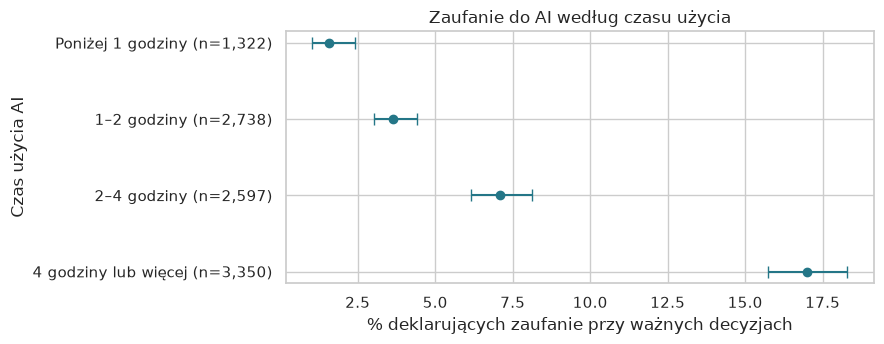

In [4]:
time_labels = {
    "<1 hour every day": "Poniżej 1 godziny",
    "1-2 hours/day": "1–2 godziny",
    "2-4 hours/day": "2–4 godziny",
    "4+ hours/day": "4 godziny lub więcej",
}
trust_sample = responses[["AIDaily", "AITrust"]].dropna()
trust_sample = trust_sample.loc[trust_sample["AIDaily"].isin(time_labels)]
counts = pd.crosstab(trust_sample["AIDaily"], trust_sample["AITrust"]).reindex(
    list(time_labels), fill_value=0
)
group_sizes = counts.sum(axis=1)
counts = counts.loc[group_sizes.gt(0)]
group_sizes = counts.sum(axis=1)
trust_label = "I trust it for many tasks, including important work decisions"
successes = counts.get(trust_label, pd.Series(0, index=counts.index))
rates = successes.div(group_sizes)
low, high = proportion_confint(successes, group_sizes, method="wilson")
cramers_v = association(counts.to_numpy(), method="cramer")
print(f"V Craméra: {cramers_v:.3f} | Podstawa: {group_sizes.sum():,} osób")
display(counts.div(group_sizes, axis=0).mul(100).rename(index=time_labels).round(1))

fig, ax = plt.subplots(figsize=(9, 3.6))
positions = np.arange(len(counts))
ax.errorbar(100 * rates, positions,
            xerr=100 * np.vstack([rates - low, high - rates]).clip(min=0),
            fmt="o", color="#247687", capsize=4)
ax.set_yticks(positions, [f"{time_labels[k]} (n={group_sizes[k]:,})" for k in counts.index])
ax.invert_yaxis()
ax.set(xlabel="% deklarujących zaufanie przy ważnych decyzjach",
       ylabel="Czas użycia AI", title="Zaufanie do AI według czasu użycia")
plt.tight_layout()
plt.show()

## 4. Co zbadać dalej?

Podsumowanie pobiera wyniki z tabel powyżej i wskazuje trzy kierunki dalszej analizy. Każdy dotyczy innego pytania badawczego i ma określoną grupę odniesienia.

In [5]:
strongest = rule_table.iloc[0]
display(Markdown(
    f"- **Współwybór narzędzi.** Para „{strongest['A']}” i „{strongest['B']}” "
    f"ma lift **{strongest['lift']:.2f}**. Sprawdź, czy podobny wzorzec utrzymuje się "
    "osobno w grupach o różnych rolach i poziomach doświadczenia.\n"
    f"- **Czas i zaufanie.** W tej grupie V Craméra wynosi **{cramers_v:.3f}**. "
    "Porównaj rozkłady zaufania po wydzieleniu podobnych grup zawodowych i stażu. "
    "Raportuj liczebności każdej podgrupy.\n"
    "- **Dobór grupy.** Przed porównaniem adopcji AI między grupami zatrudnienia "
    "zestaw pokrycie pytania i udział jawnych odpowiedzi „Nie używam” wśród osób z zapisem. "
    "To pozwoli odróżnić słabą obserwowalność pytania od niskiej deklarowanej adopcji."
))

- **Współwybór narzędzi.** Para „Agenci lub automatyzacje” i „Firmowe narzędzia AI” ma lift **1.94**. Sprawdź, czy podobny wzorzec utrzymuje się osobno w grupach o różnych rolach i poziomach doświadczenia.
- **Czas i zaufanie.** W tej grupie V Craméra wynosi **0.183**. Porównaj rozkłady zaufania po wydzieleniu podobnych grup zawodowych i stażu. Raportuj liczebności każdej podgrupy.
- **Dobór grupy.** Przed porównaniem adopcji AI między grupami zatrudnienia zestaw pokrycie pytania i udział jawnych odpowiedzi „Nie używam” wśród osób z zapisem. To pozwoli odróżnić słabą obserwowalność pytania od niskiej deklarowanej adopcji.